# Customer Segmentation Using 10 Algorithms from the ML Lab Syllabus

**Dataset:** `Mall_Customers.csv` (200 customers)
**Features:** Age, Annual Income (k$), Spending Score (1-100)
**Learning type:** Unsupervised clustering, plus supervised classifiers that learn the segments

This notebook uses only algorithms that appear in the ML lab codes (Labs 1-29). The labs contain only three clustering algorithms, so the other seven are supervised classifiers. They are trained to predict the segment that K-Means assigns to each customer, which lets them be compared on the same data.

| # | Algorithm | Lab source | Role in this notebook |
|---|---|---|---|
| 1 | K-Means | Labs 22, 26 | Segmentation |
| 2 | Agglomerative (Hierarchical), Ward linkage | Labs 23, 26 | Segmentation |
| 3 | DBSCAN | Labs 24, 26 | Segmentation |
| 4 | Logistic Regression | Labs 14-15, 20 | Classifies segments |
| 5 | Decision Tree | Labs 1-6, 16, 20 | Classifies segments |
| 6 | Random Forest | Labs 17, 20, 28 | Classifies segments |
| 7 | K-Nearest Neighbors | Labs 18, 20 | Classifies segments |
| 8 | Support Vector Machine (RBF kernel) | Labs 19, 20 | Classifies segments |
| 9 | Gaussian Naive Bayes | Labs 1-6, 20 | Classifies segments |
| 10 | Multi-Layer Perceptron (MLP) | Labs 27-29 | Classifies segments |


## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    classification_report, confusion_matrix
)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

print("Libraries imported.")


Libraries imported.


## 2. Load the Dataset

In [2]:
DATA_PATH = "ML_Programming/Data Sets/Data Sets/Mall_Customers.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "Mall_Customers.csv was not found. Update DATA_PATH with the correct file path."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print(df.head().to_string())


Dataset shape: (200, 5)
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


## 3. Understand and Check the Data

In [3]:
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes.to_string())
print("\nMissing values:")
print(df.isnull().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
print(df.describe().round(2).to_string())


Columns: ['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data types:
CustomerID                 int64
Genre                     object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0

Duplicate rows: 0

Summary statistics:
       CustomerID     Age  Annual Income (k$)  Spending Score (1-100)
count      200.00  200.00              200.00                  200.00
mean       100.50   38.85               60.56                   50.20
std         57.88   13.97               26.26                   25.82
min          1.00   18.00               15.00                    1.00
25%         50.75   28.75               41.50                   34.75
50%        100.50   36.00               61.50                   50.00
75%        150.25   49.00               78.00  

## 4. Select Features and Scale Them

The three numerical features are standardised so each has mean 0 and standard deviation 1. Without scaling, income (in thousands) would dominate the distance calculations. The `Genre` and `CustomerID` columns are not used.


In [4]:
feature_columns = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = df[feature_columns].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print(pd.DataFrame(X_scaled, columns=feature_columns).head().round(3).to_string())


Scaled data shape: (200, 3)
     Age  Annual Income (k$)  Spending Score (1-100)
0 -1.425              -1.739                  -0.435
1 -1.281              -1.739                   1.196
2 -1.353              -1.701                  -1.716
3 -1.138              -1.701                   1.040
4 -0.563              -1.663                  -0.396


## 5. Choosing the Number of Clusters (Elbow and Silhouette, Lab 26)

The elbow method plots inertia (within-cluster sum of squares) against K. The silhouette score is also computed for each K from 2 to 10. Both are used to justify K = 5 for the K-Means and hierarchical models below.


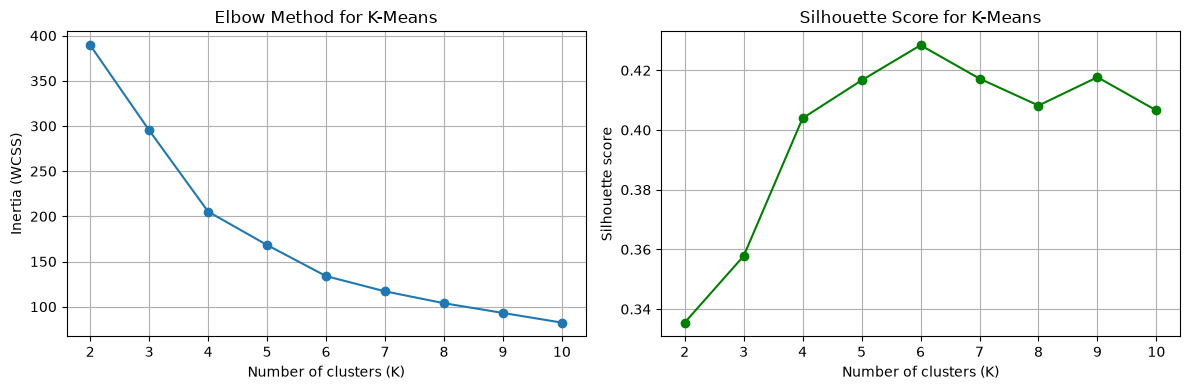

 K  Inertia  Silhouette
 2   389.39      0.3355
 3   295.21      0.3578
 4   205.23      0.4040
 5   168.25      0.4166
 6   133.87      0.4284
 7   117.01      0.4172
 8   103.87      0.4082
 9    93.09      0.4177
10    82.39      0.4066


In [5]:
k_values = list(range(2, 11))
inertias, sil_scores = [], []

for k in k_values:
    km_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km_k.fit_predict(X_scaled)
    inertias.append(km_k.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels_k))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_values, inertias, marker="o")
ax[0].set_title("Elbow Method for K-Means")
ax[0].set_xlabel("Number of clusters (K)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[0].grid(True)

ax[1].plot(k_values, sil_scores, marker="o", color="green")
ax[1].set_title("Silhouette Score for K-Means")
ax[1].set_xlabel("Number of clusters (K)")
ax[1].set_ylabel("Silhouette score")
ax[1].grid(True)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"K": k_values, "Inertia": np.round(inertias, 2),
                    "Silhouette": np.round(sil_scores, 4)}).to_string(index=False))


## 6. Algorithm 1: K-Means Clustering (Lab 22)

K-Means groups customers into a fixed number of clusters (K = 5 here) by repeatedly assigning each customer to the nearest centre and updating the centres.


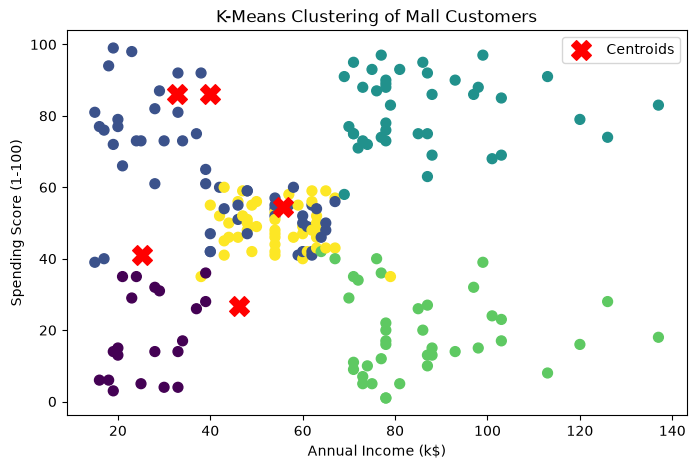

Number of clusters: 5
Inertia: 168.25

Customers in each cluster:
0    20
1    54
2    40
3    39
4    47


In [6]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)

df["KMeans_Cluster"] = labels_kmeans
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"],
            c=labels_kmeans, cmap="viridis", s=50)
plt.scatter(centers[:, 0], centers[:, 1], color="red", marker="X", s=200, label="Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Clustering of Mall Customers")
plt.legend()
plt.show()

print("Number of clusters:", len(set(labels_kmeans)))
print("Inertia:", round(kmeans.inertia_, 2))
print("\nCustomers in each cluster:")
print(pd.Series(labels_kmeans).value_counts().sort_index().to_string())


## 7. Algorithm 2: Agglomerative (Hierarchical) Clustering with Ward Linkage (Lab 23)

Hierarchical clustering starts with each customer as its own cluster and repeatedly merges the closest clusters. The dendrogram below uses the first 100 customers so that it stays readable.


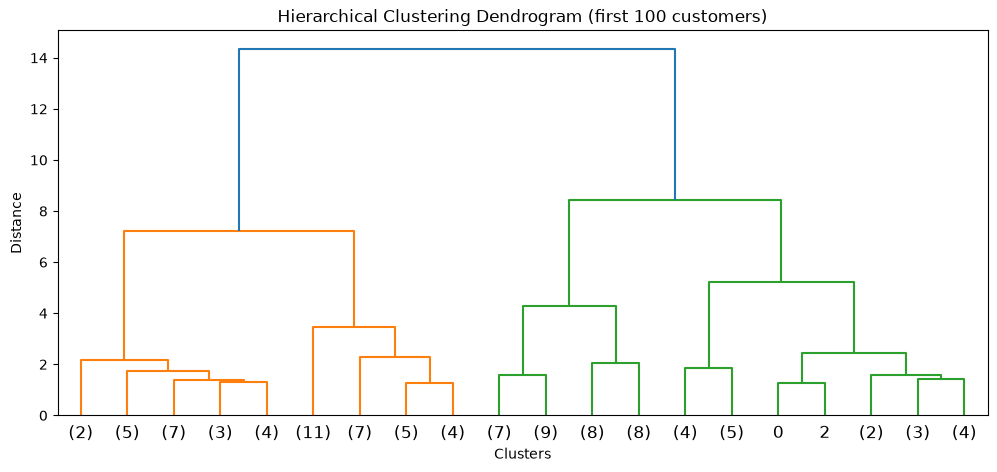

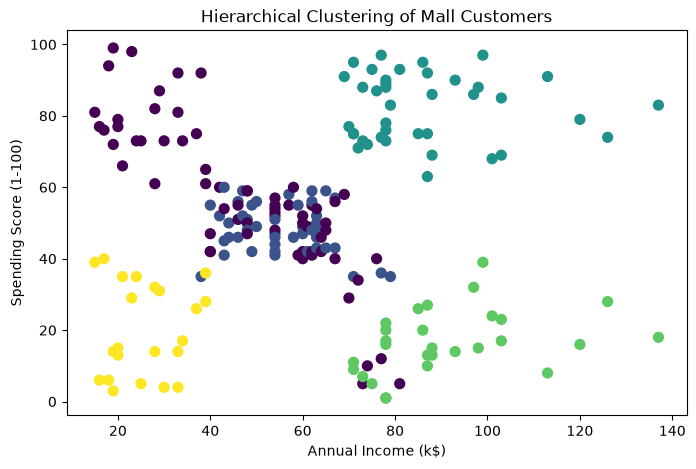

Number of clusters: 5

Customers in each cluster:
0    66
1    45
2    39
3    28
4    22


In [7]:
sample = X_scaled[:100]
Z = linkage(sample, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.title("Hierarchical Clustering Dendrogram (first 100 customers)")
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.show()

agg = AgglomerativeClustering(n_clusters=5, linkage="ward")
labels_agg = agg.fit_predict(X_scaled)
df["Hierarchical_Cluster"] = labels_agg

plt.figure(figsize=(8, 5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"],
            c=labels_agg, cmap="viridis", s=50)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Hierarchical Clustering of Mall Customers")
plt.show()

print("Number of clusters:", len(set(labels_agg)))
print("\nCustomers in each cluster:")
print(pd.Series(labels_agg).value_counts().sort_index().to_string())


## 8. Algorithm 3: DBSCAN (Lab 24)

DBSCAN forms clusters from dense regions and labels isolated customers as noise (-1). The lab settings are `eps=0.35` and `min_samples=5`.


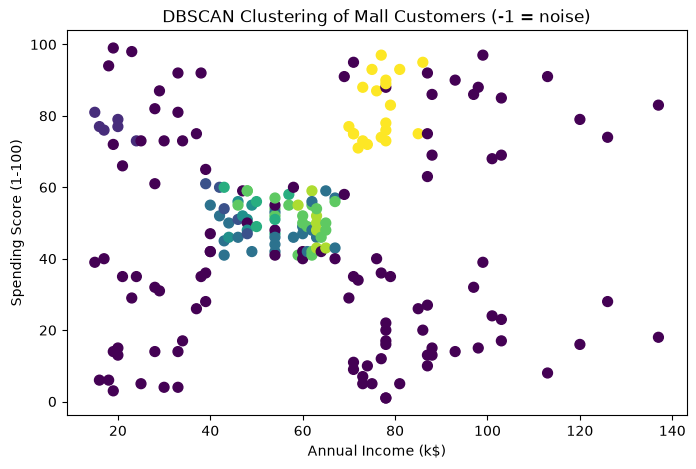

Number of clusters: 8
Number of noise points: 110

Customers in each cluster (-1 = noise):
-1    110
 0      6
 1      5
 2     21
 3      6
 4      6
 5     19
 6      7
 7     20


In [8]:
dbscan = DBSCAN(eps=0.35, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)
df["DBSCAN_Cluster"] = labels_dbscan

plt.figure(figsize=(8, 5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"],
            c=labels_dbscan, cmap="viridis", s=50)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("DBSCAN Clustering of Mall Customers (-1 = noise)")
plt.show()

print("Number of clusters:", len(set(labels_dbscan) - {-1}))
print("Number of noise points:", int((labels_dbscan == -1).sum()))
print("\nCustomers in each cluster (-1 = noise):")
print(pd.Series(labels_dbscan).value_counts().sort_index().to_string())


## 9. Compare the Three Clustering Algorithms (Lab 26)

The metrics are calculated for each algorithm. For DBSCAN, noise points are excluded from the calculation, so its scores describe only the customers it grouped.


In [9]:
def clustering_metrics(X_values, labels):
    mask = labels != -1
    X_eval, labels_eval = X_values[mask], labels[mask]
    n_clusters = len(np.unique(labels_eval))
    row = {
        "Clusters": n_clusters,
        "Noise points": int((labels == -1).sum()),
        "Points scored": int(mask.sum()),
        "Silhouette": np.nan,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan,
    }
    if 2 <= n_clusters < len(X_eval):
        row["Silhouette"] = silhouette_score(X_eval, labels_eval)
        row["Davies-Bouldin"] = davies_bouldin_score(X_eval, labels_eval)
        row["Calinski-Harabasz"] = calinski_harabasz_score(X_eval, labels_eval)
    return row

comparison = pd.DataFrame({
    "K-Means": clustering_metrics(X_scaled, labels_kmeans),
    "Agglomerative (Ward)": clustering_metrics(X_scaled, labels_agg),
    "DBSCAN (eps=0.35)": clustering_metrics(X_scaled, labels_dbscan),
}).T
print(comparison.round(4).to_string())


                      Clusters  Noise points  Points scored  Silhouette  Davies-Bouldin  Calinski-Harabasz
K-Means                    5.0           0.0          200.0      0.4166          0.8746           125.1009
Agglomerative (Ward)       5.0           0.0          200.0      0.3900          0.9163           107.8266
DBSCAN (eps=0.35)          8.0         110.0           90.0      0.4900          0.6812           164.8895


**Reading the comparison:**

- **K-Means and Agglomerative** both assign all 200 customers. K-Means scores better on all three metrics (silhouette 0.4166 vs 0.3900, Davies-Bouldin 0.8746 vs 0.9163, Calinski-Harabasz 125.1 vs 107.8).
- **DBSCAN** has the highest raw scores (silhouette 0.4900), but it labels **110 of 200 customers (55%) as noise**. Its scores describe only the 90 customers it grouped, so it is not suitable for segmenting the whole customer base with these settings.
- Metric scores are geometric measures. They support K-Means as the most reliable of the three, but the segment meanings still need to be checked against the profile below.


## 10. Interpret the Customer Segments

Cluster numbers are labels only. The average values of each feature show what each K-Means segment represents.


                  Age  Annual Income (k$)  Spending Score (1-100)  Customers
KMeans_Cluster                                                              
0               46.25               26.75                   18.35         20
1               25.19               41.09                   62.24         54
2               32.88               86.10                   81.53         40
3               39.87               86.10                   19.36         39
4               55.64               54.38                   48.85         47


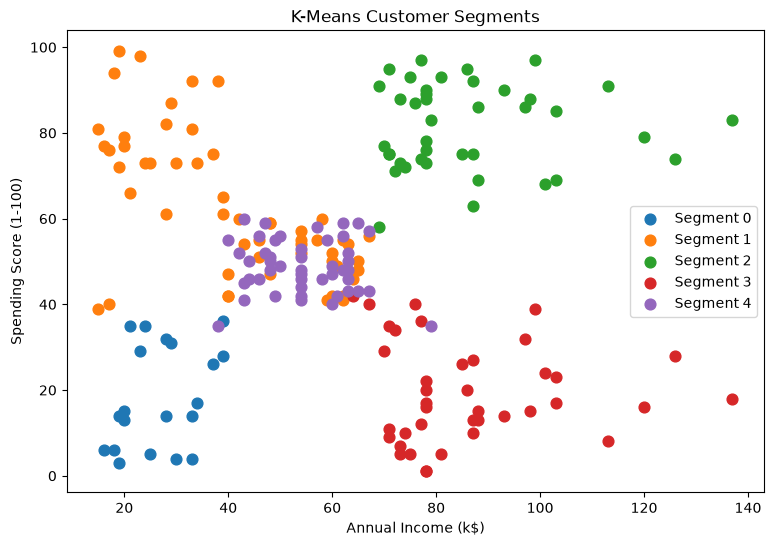

In [10]:
profile = df.groupby("KMeans_Cluster")[feature_columns].mean().round(2)
profile["Customers"] = df["KMeans_Cluster"].value_counts().sort_index()
print(profile.to_string())

plt.figure(figsize=(9, 6))
for c in sorted(df["KMeans_Cluster"].unique()):
    sub = df[df["KMeans_Cluster"] == c]
    plt.scatter(sub["Annual Income (k$)"], sub["Spending Score (1-100)"], s=60, label=f"Segment {c}")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Customer Segments")
plt.legend()
plt.show()


**Describing the five K-Means segments (from the averages above):**

- **Segment 0 (20 customers):** older on average, lowest income and lowest spending. A low-engagement group.
- **Segment 1 (54 customers):** youngest group (average age 25), moderate income, high spending. Enthusiastic younger shoppers, the largest segment.
- **Segment 2 (40 customers):** high income and high spending. The likely premium customers.
- **Segment 3 (39 customers):** high income but low spending. Customers who can afford more but are not currently spending, a possible target for campaigns.
- **Segment 4 (47 customers):** middle-aged (average age 56), middle income, average spending.


## 11. Supervised Classifiers on the K-Means Segments (Labs 14-21, 27-29)

The seven classifiers below learn to predict the K-Means segment from age, income, and spending score. The segment labels come from the clustering step, so this tests how well each classifier can reproduce the segment boundaries. Each model is scored on a held-out 20% test set and with 5-fold cross-validation on all data.


In [11]:
y = df["KMeans_Cluster"].values
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "K-Nearest Neighbors (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF kernel)": SVC(kernel="rbf", random_state=42),
    "Gaussian Naive Bayes": GaussianNB(),
    "MLP (one hidden layer, 50 units)": MLPClassifier(hidden_layer_sizes=(50,), max_iter=2000, random_state=42),
}

clf_rows = {}
for name, model in classifiers.items():
    model.fit(X_train, y_train)
    cv_scores = cross_val_score(model, X_scaled, y, cv=5)
    clf_rows[name] = {
        "Test accuracy": model.score(X_test, y_test),
        "CV mean accuracy": cv_scores.mean(),
        "CV std": cv_scores.std(),
    }

clf_results = pd.DataFrame(clf_rows).T.sort_values("CV mean accuracy", ascending=False)
print(clf_results.round(4).to_string())


                                  Test accuracy  CV mean accuracy  CV std
Logistic Regression                       0.975             0.975  0.0224
MLP (one hidden layer, 50 units)          0.975             0.960  0.0339
Gaussian Naive Bayes                      0.975             0.950  0.0447
SVM (RBF kernel)                          1.000             0.940  0.0644
K-Nearest Neighbors (k=5)                 0.925             0.935  0.0583
Random Forest                             1.000             0.930  0.0748
Decision Tree                             1.000             0.895  0.1100


In [12]:
best_name = clf_results.index[0]
best_model = classifiers[best_name]
y_pred = best_model.predict(X_test)

print("Best classifier by cross-validation:", best_name)
print("\nClassification report on the test set:")
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion matrix (rows = actual segment, columns = predicted segment):")
print(confusion_matrix(y_test, y_pred))


Best classifier by cross-validation: Logistic Regression

Classification report on the test set:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00        11
           2       1.00      1.00      1.00         8
           3       0.89      1.00      0.94         8
           4       1.00      0.89      0.94         9

    accuracy                           0.97        40
   macro avg       0.98      0.98      0.98        40
weighted avg       0.98      0.97      0.97        40

Confusion matrix (rows = actual segment, columns = predicted segment):
[[ 4  0  0  0  0]
 [ 0 11  0  0  0]
 [ 0  0  8  0  0]
 [ 0  0  0  8  0]
 [ 0  0  0  1  8]]


## 12. Save the Model and Scaler

The K-Means model and the scaler are saved together. The same scaler must be used before assigning any new customer to a segment.


In [13]:
joblib.dump(kmeans, "kmeans_customer_model.pkl")
joblib.dump(scaler, "customer_feature_scaler.pkl")
print("Saved kmeans_customer_model.pkl")
print("Saved customer_feature_scaler.pkl")


Saved kmeans_customer_model.pkl
Saved customer_feature_scaler.pkl


**Reading the classifier results:**

- All seven classifiers reach at least 92.5% test accuracy.
- **Logistic Regression** has the highest cross-validated accuracy (97.5%, standard deviation 2.2%), so it is the most consistent choice on this data.
- Decision Tree, Random Forest, and SVM reach 100% on the 40-customer test set, but their cross-validation scores are lower (89.5% to 94%). The small test set makes single test scores unreliable.
- These classifiers learn labels that came from the same three features, so high accuracy shows the segments are learnable, not that they are correct for the business.


## 13. Summary of the Ten Algorithms

- **Clustering (unsupervised):** K-Means, Agglomerative (Ward), and DBSCAN were compared using silhouette, Davies-Bouldin, and Calinski-Harabasz scores, the number of clusters, and the noise count.
- **Classification (supervised):** Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors, SVM (RBF), Gaussian Naive Bayes, and MLP were trained to reproduce the K-Means segments and compared by test accuracy and cross-validation.
- **Limitation:** the classifiers learn labels that were derived from the same three features, so their high accuracy shows that the segments are learnable, not that the segments are correct for the business.
